# Fernando Dias





#📊 Análise de Dados com Python - Spotify 2025

> Adicionar aspas



## Autoria: Fernando Dias
## Data: Outubro de 2026


## ▶ Introdução
       
####  Este notebook demostra uma estrutura padrão para iniciar uma análise de dados

Link/dataset: https://www.kaggle.com/datasets/kylefengkfeng209/most-streamed-spotify-songs-2025?utm_source=chatgpt.com

## 📁 1. Importação das Bibliotecas

In [47]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

## 📊 2. Importação dos Dados

In [48]:
# Carregando os dados
df = pd.read_csv('/content/most_streamed_spotify_2025.csv')
df

,rank,track,artist,billed_artist_count,is_collaboration,spotify_streams_total,daily_streams,daily_streams_rank,daily_stream_share_pct,wrapped_global_top10_rank
0,1,Ordinary,Alex Warren,1,False,1948570210,2333502,11,0.1198,4.0
1,2,DtMF,Bad Bunny,1,False,1912497312,3017476,3,0.1578,5.0
2,3,Golden,HUNTR/X,1,False,1759912501,2286960,14,0.1299,7.0
3,4,BAILE INoLVIDABLE,Bad Bunny,1,False,1553054400,2624716,7,0.1690,NaN
4,5,The Fate of Ophelia,Taylor Swift,1,False,1425834222,3046797,2,0.2137,NaN
...,...,...,...,...,...,...,...,...,...,...
725,726,Bete Balanço,Barão Vermelho,1,False,100802110,50986,666,0.0506,NaN
726,727,Dance With My Father,Luther Vandross,1,False,100667340,37443,691,0.0372,NaN
727,728,Piel Morena,Thalia,1,False,100633015,41238,684,0.0410,NaN
728,729,Clave Privada,Banda El Recodo,1,False,100615715,141056,488,0.1402,NaN


## 🧹 3. Preparação dos Dados

In [49]:
df = df.rename(columns={
     'rank': 'Rank',
     'track': 'Música',
     'artist': 'Artista',
     'billed_artist_count': 'Número de artistas',
     'is_collaboration': 'Colaboração',
     'spotify_streams_total': 'Total_de_reproduções',
     'daily_streams': 'Reproduções diárias',
     'daily_streams_rank': 'Rank_de_reproduções diárias',
     'daily_stream_share_pct': 'Porcentagem_reprodução diária',
     'wrapped_global_top10_rank': 'Top 10 rank',
     })


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Rank                           730 non-null    int64  
 1   Música                         730 non-null    object 
 2   Artista                        730 non-null    object 
 3   Número de artistas             730 non-null    int64  
 4   Colaboração                    730 non-null    bool   
 5   Total_de_reproduções           730 non-null    int64  
 6   Reproduções diárias            730 non-null    int64  
 7   Rank_de_reproduções diárias    730 non-null    int64  
 8   Porcentagem_reprodução diária  730 non-null    float64
 9   Top 10 rank                    3 non-null      float64
dtypes: bool(1), float64(2), int64(5), object(2)
memory usage: 52.2+ KB


Resumo:
A tabela tem 730 linhas e 10 colunas.
As colunas numéricas estão com tipos adequados: int64 e float64. Colaboração está como bool: verdadeiro ou falso.
top10_rank tem apenas 3 valores preenchidos.

In [64]:
df

,Rank,Música,Artista,Número de artistas,Colaboração,Total_de_reproduções,Reproduções diárias,Rank_de_reproduções diárias,Porcentagem_reprodução diária,Top 10 rank
0,1,Ordinary,Alex Warren,1,False,1948570210,2333502,11,0.1198,4.0
1,2,DtMF,Bad Bunny,1,False,1912497312,3017476,3,0.1578,5.0
2,3,Golden,HUNTR/X,1,False,1759912501,2286960,14,0.1299,7.0
3,4,BAILE INoLVIDABLE,Bad Bunny,1,False,1553054400,2624716,7,0.1690,NaN
4,5,The Fate of Ophelia,Taylor Swift,1,False,1425834222,3046797,2,0.2137,NaN
...,...,...,...,...,...,...,...,...,...,...
725,726,Bete Balanço,Barão Vermelho,1,False,100802110,50986,666,0.0506,NaN
726,727,Dance With My Father,Luther Vandross,1,False,100667340,37443,691,0.0372,NaN
727,728,Piel Morena,Thalia,1,False,100633015,41238,684,0.0410,NaN
728,729,Clave Privada,Banda El Recodo,1,False,100615715,141056,488,0.1402,NaN


##Com base nos dados analisados, vamos responder as seguintes perguntas:



1.   Quais são as 10 músicas com mais reporduções acumuladas?
2.   Quais são as 10 músicas com mais reproduções diárias?
3.   Quais músicas aparecem nos dois Top10?
4.   Quais artistas soma maios reproduções acumuladas?
5.   Quais artistas possuem mias registros na base?
6.   Quantos os 10 maiores registros representam no total de reproduções acumuladas?
7.   Entre os artistas com pelo menos 3 registros na base, quais têm a maior média de reproduções acumuladas por registro?







## 🔍 4. Análise Exploratório

In [52]:
# Conta os valores ausentes na coluna top 10 rank
df['Top 10 rank'].isna().sum()

np.int64(727)

In [53]:
# Conta as linhas que repetem todos os valores de outra linha
df.duplicated().sum()

np.int64(0)

In [54]:
# Exibe os nomes atuais das colunas
df.columns.tolist()

['Rank',
 'Música',
 'Artista',
 'Número de artistas',
 'Colaboração',
 'Total_de_reproduções',
 'Reproduções diárias',
 'Rank_de_reproduções diárias',
 'Porcentagem_reprodução diária',
 'Top 10 rank']

In [56]:
# Mostra todas as linhas em que a combinação de música e artista se repete
df[df.duplicated(subset=['Música', 'Artista'], keep=False)]

,Rank,Música,Artista,Número de artistas,Colaboração,Total_de_reproduções,Reproduções diárias,Rank_de_reproduções diárias,Porcentagem_reprodução diária,Top 10 rank
32,33,Show Me Love,WizTheMc,1,False,643142920,929630,55,0.1445,NaN
134,135,Show Me Love,WizTheMc,1,False,300140092,539297,136,0.1797,NaN
165,166,Triple Lavada,Esau Ortiz,1,False,263265257,265525,310,0.1009,NaN
208,209,NO BATIDÃO,ZXKAI,1,False,227521371,580132,118,0.2550,NaN
223,224,MONTAGEM TOMADA,MXZI,1,False,219537183,161554,454,0.0736,NaN
240,241,NO BATIDÃO,ZXKAI,1,False,212941320,706434,90,0.3318,NaN
436,437,MONTAGEM TOMADA,MXZI,1,False,148708414,89711,587,0.0603,NaN
617,618,Triple Lavada,Esau Ortiz,1,False,116743517,165313,442,0.1416,NaN


Resumo:
Os números de reproduções são diferentes em cada ocorrência. Sem um identificador da faixa.

In [57]:
# Mostra estatísticas das reproduções acumuladas e diárias
df[['Total_de_reproduções', 'Reproduções diárias']].describe()

,Total_de_reproduções,Reproduções diárias
count,7.300000e+02,7.300000e+02
mean,2.337006e+08,3.684854e+05
std,2.075011e+08,4.639724e+05
min,1.002850e+08,9.432000e+03
25%,1.266382e+08,1.106278e+05
50%,1.670339e+08,2.229660e+05
75%,2.456286e+08,4.337102e+05
max,1.948570e+09,3.075070e+06


Resumo:
A média soma as reproduções e divide pelos 730 registros. Já a mediana representa o centro dos dados ordenados: metade dos registros fica abaixo ou igual a ela e metade acima ou igual.
Nas duas colunas, a média está acima da mediana. Isso indica uma distribuição com valores altos que elevam a média.

In [58]:
# Seleciona os 10 maiores valores de reproduções acumuladas
top_10 = df.nlargest(10, 'Total_de_reproduções')

# Exibe apenas as colunas necessárias para analisar o ranking
top_10[['Música', 'Artista', 'Total_de_reproduções']]

,Música,Artista,Total_de_reproduções
0,Ordinary,Alex Warren,1948570210
1,DtMF,Bad Bunny,1912497312
2,Golden,HUNTR/X,1759912501
3,BAILE INoLVIDABLE,Bad Bunny,1553054400
4,The Fate of Ophelia,Taylor Swift,1425834222
5,NUEVAYoL,Bad Bunny,1304961163
6,Man I Need,Olivia Dean,1163100298
7,EoO,Bad Bunny,1134697302
8,La Plena,W Sound,1122378160
9,VOY A LLeVARTE PA PR,Bad Bunny,983744897


Resuno:
Ordinary” lidera com cerca de 1,95 bilhão de reproduções, e Bad Bunny aparece em 5 dos 10 registros.

In [61]:
# Seleciona os 10 registros com mais reproduções diárias
top_10_diario = df.nlargest(10, 'Reproduções diárias')

# Exibe música, artista e quantidade de reproduções diárias
top_10_diario[['Música', 'Artista', 'Reproduções diárias']]

,Música,Artista,Reproduções diárias
6,Man I Need,Olivia Dean,3075070
4,The Fate of Ophelia,Taylor Swift,3046797
1,DtMF,Bad Bunny,3017476
68,Choosin' Texas,Ella Langley,2929067
11,Clean Baby Sleep White Noise (Loopable no fade),Dream Supplier,2763626
37,Raindance,Dave,2762424
3,BAILE INoLVIDABLE,Bad Bunny,2624716
43,Stateside + Zara Larsson,PinkPantheress,2537274
17,So Easy (To Fall In Love),Olivia Dean,2534851
19,WHERE IS MY HUSBAND!,RAYE,2444119


Resumo:

Man I Need, de Olivia Dean, lidera com 3.075.070 reproduções diárias.

The Fate of Ophelia, de Taylor Swift, aparece em segundo, com 3.046.797.

DtMF, de Bad Bunny, ocupa o terceiro lugar, com 3.017.476.

Olivia Dean e Bad Bunny possuem duas músicas cada nesse Top 10.

In [65]:
# Cruza os dois rankings usando música e artista
musicas_em_comum = top_10[
    ['Música', 'Artista', 'Total_de_reproduções']
].merge(
    top_10_diario[['Música', 'Artista', 'Reproduções diárias']],
    on=['Música', 'Artista'],
    how='inner'
)

# Exibe as músicas presentes nos dois rankings
musicas_em_comum

,Música,Artista,Total_de_reproduções,Reproduções diárias
0,DtMF,Bad Bunny,1912497312,3017476
1,BAILE INoLVIDABLE,Bad Bunny,1553054400,2624716
2,The Fate of Ophelia,Taylor Swift,1425834222,3046797
3,Man I Need,Olivia Dean,1163100298,3075070


Resumo:
quatro músicas se destacam tanto em reproduções acumuladas quanto no volume diário informado. Elas representam 40% das posições de cada Top 10 — esse percentual se refere à quantidade de músicas, não às reproduções.

In [66]:
# Agrupa os registros por artista e soma as reproduções acumuladas
reproducoes_por_artista = (
    df.groupby('Artista')['Total_de_reproduções']
    .sum()
    .reset_index()
)

# Seleciona os 10 artistas com os maiores totais
top_10_artistas = reproducoes_por_artista.nlargest(
    10, 'Total_de_reproduções'
)

# Exibe o ranking
top_10_artistas

,Artista,Total_de_reproduções
23,Bad Bunny,11246823766
336,Taylor Swift,4769621849
300,Sabrina Carpenter,4047388152
265,Olivia Dean,3776232333
127,HUNTR/X,3519605700
335,Tate McRae,3468687807
112,Fuerza Regida,3256811633
10,Alex Warren,2807625539
259,Neton Vega,2543530779
244,Morgan Wallen,2257716361


Resumo:
agrupando os registros por artista, somamos suas reproduções acumuladas e selecionamos os 10 maiores totais.

Bad Bunny lidera com mais que o dobro do total de Taylor Swift, segunda colocada. Alex Warren, embora tenha a música líder no ranking acumulado, aparece em oitavo quando somamos os registros por artista.

In [67]:
# Conta quantos registros existem para cada artista
quantidade_por_artista = (
    df.groupby('Artista')
    .size()
    .reset_index(name='Quantidade_de_registros')
)

# Ordena pela quantidade e usa o nome como desempate
top_10_quantidade = quantidade_por_artista.sort_values(
    by=['Quantidade_de_registros', 'Artista'],
    ascending=[False, True]
).head(10)

# Exibe os 10 primeiros artistas
top_10_quantidade

,Artista,Quantidade_de_registros
23,Bad Bunny,15
300,Sabrina Carpenter,14
336,Taylor Swift,12
259,Neton Vega,10
335,Tate McRae,10
112,Fuerza Regida,9
244,Morgan Wallen,9
265,Olivia Dean,9
275,Peso Pluma,8
33,Beéle,7


Resumo:
Bad Bunny lidera tanto em quantidade de registros quanto em reproduções acumuladas. Porém, ter mais registros não garante um total maior.

Sabrina Carpenter possui 14 registros, mas soma menos reproduções que Taylor Swift, que possui 12.

In [68]:
# Soma as reproduções acumuladas de todos os registros
total_base = df['Total_de_reproduções'].sum()

# Soma as reproduções acumuladas do Top 10
total_top_10 = top_10['Total_de_reproduções'].sum()

# Calcula a participação percentual do Top 10
participacao_top_10 = total_top_10 / total_base * 100

# Exibe o percentual com duas casas decimais
print(f'Participação do Top 10 nas reproduções da base: {participacao_top_10:.2f}%')

Participação do Top 10 nas reproduções da base: 8.39%


Resumo:
Os 10 registros correspondem a aproximadamente 1,37% dos 730 registros, mas respondem por 8,39% das reproduções. Portanto, sua participação nas reproduções é proporcionalmente maior que sua participação na quantidade de registros.


In [70]:
# Calcula a quantidade de registros e a média de reproduções por artista
resumo_artistas = (
    df.groupby('Artista')
    .agg(
        Quantidade_de_registros=('Total_de_reproduções', 'size'),
        Media_de_reproducoes=('Total_de_reproduções', 'mean')
    )
    .reset_index()
)

# Mantém somente artistas com pelo menos 3 registros
artistas_com_minimo_3 = resumo_artistas[
    resumo_artistas['Quantidade_de_registros'] >= 3
]

# Seleciona os 10 artistas com as maiores médias
top_10_media = artistas_com_minimo_3.nlargest(
    10, 'Media_de_reproducoes'
)

# Exibe o resultado
top_10_media

,Artista,Quantidade_de_registros,Media_de_reproducoes
127,HUNTR/X,4,8.799014e+08
23,Bad Bunny,15,7.497883e+08
10,Alex Warren,4,7.019064e+08
399,sombr,3,6.099093e+08
167,KATSEYE,3,5.517304e+08
265,Olivia Dean,9,4.195814e+08
336,Taylor Swift,12,3.974685e+08
164,Justin Bieber,4,3.708712e+08
371,WizTheMc,3,3.706651e+08
343,The Smashing Pumpkins,3,3.677851e+08


Resuno:
HUNTR/X lidera a média entre os artistas que atendem ao filtro, com aproximadamente 879,9 milhões por registro.

Bad Bunny lidera em total acumulado e quantidade de registros, mas fica em segundo na média.

O artista com maior total não precisa ter a maior média por registro. A média também pode ser influenciada por uma música com muitas reproduções, portanto não demonstra que todas as faixas têm desempenho semelhante.

## 📈 5. Visualização de Dados


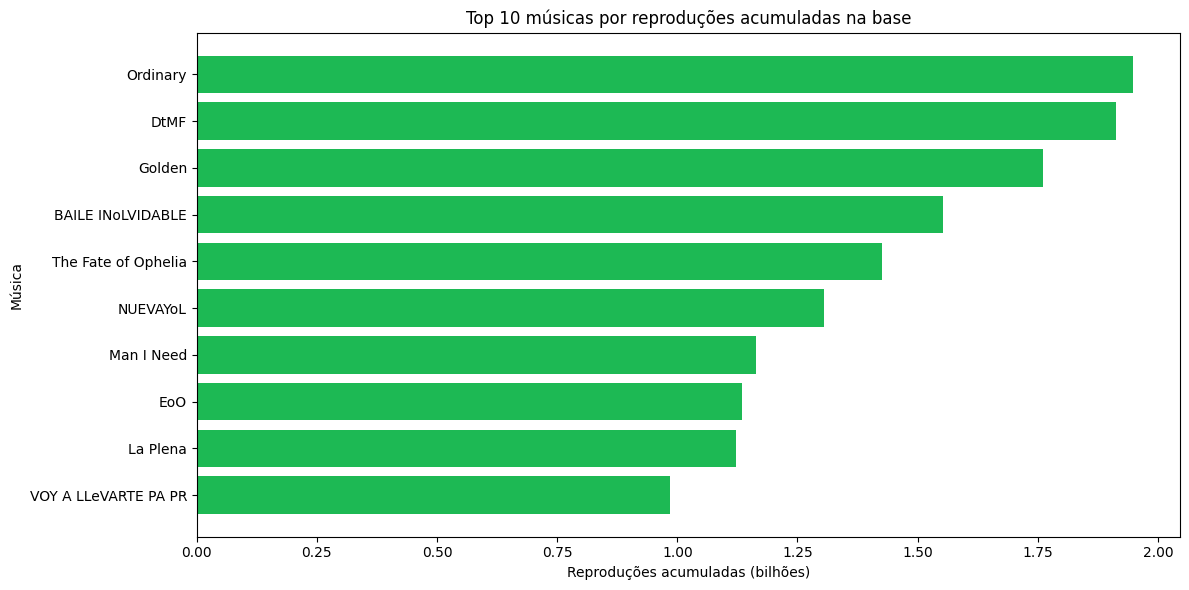

In [71]:
# Usando gráficos

# Define o tamanho do gráfico
plt.figure(figsize=(12, 6))

# Cria as barras com os valores convertidos para bilhões
plt.barh(
    top_10['Música'],
    top_10['Total_de_reproduções'] / 1_000_000_000,
    color='#1DB954'
)

# Coloca a música com mais reproduções no topo
plt.gca().invert_yaxis()

# Adiciona título e nomes dos eixos
plt.title('Top 10 músicas por reproduções acumuladas na base')
plt.xlabel('Reproduções acumuladas (bilhões)')
plt.ylabel('Música')

# Ajusta o espaçamento e exibe o gráfico
plt.tight_layout()
plt.show()

Resumo:
Aqui estamos vendo as 10 músicas mais reproduzidas e acumuladas na base e a diferença de volumes entre elas.

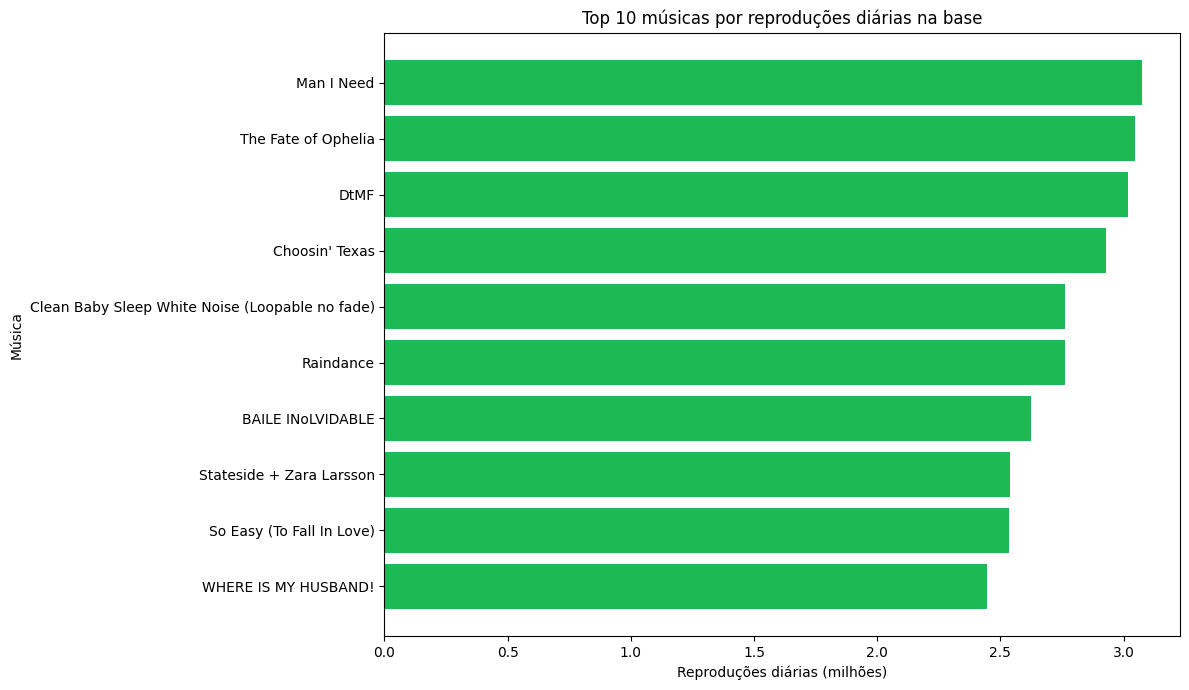

In [72]:
# Gráfico do Top10

# Define o tamanho do gráfico
plt.figure(figsize=(12, 7))

# Cria barras horizontais com os valores em milhões
plt.barh(
    top_10_diario['Música'],
    top_10_diario['Reproduções diárias'] / 1_000_000,
    color='#1DB954'
)

# Coloca o primeiro lugar no topo
plt.gca().invert_yaxis()

# Define o título e os nomes dos eixos
plt.title('Top 10 músicas por reproduções diárias na base')
plt.xlabel('Reproduções diárias (milhões)')
plt.ylabel('Música')

# Ajusta os espaços e exibe o gráfico
plt.tight_layout()
plt.show()

## 🧠 6. Conclusões


A análise dos 730 registros permitiu identificar as músicas e os artistas de maior destaque no conjunto de dados, considerando reproduções acumuladas e diárias.
“Ordinary”, de Alex Warren, liderou as reproduções acumuladas, com aproximadamente 1,95 bilhão. No volume diário informado, “Man I Need”, de Olivia Dean, ocupou a primeira posição, com 3.075.070 reproduções. Quatro músicas apareceram nos dois Top 10, representando 40% das posições de cada ranking. Isso mostra que o destaque acumulado nem sempre coincide com o destaque diário.
Bad Bunny apresentou o maior total de reproduções acumuladas por artista, com aproximadamente 11,25 bilhões, e a maior quantidade de registros, com 15. Entretanto, HUNTR/X liderou a média de reproduções acumuladas por registro entre os artistas com pelo menos três registros, alcançando aproximadamente 879,9 milhões. Portanto, total, quantidade e média oferecem perspectivas diferentes sobre o desempenho dos artistas.
Os dez maiores registros concentraram 8,39% das reproduções acumuladas, embora representem aproximadamente 1,37% dos registros da base.
O projeto demonstrou como Python e Pandas podem ser utilizados para explorar dados, construir rankings, realizar agrupamentos e calcular indicadores. As conclusões se limitam ao conjunto analisado e devem considerar a ausência de datas e as repetições não esclarecidas na fonte.

##📁 Documentação do Projeto



1.   **Objetivo**

     Identificar as músicas e os artistas de maior destaque na base, comparando reproduções acumuladas, reproduções diárias, quantidade de registros e desempenho médio por artista.




2.   **Base de dados**

     Foi utilizado o arquivo most_streamed_spotify_2025.csv, fornecido para o projeto, contendo 730 registros e 10 colunas.

     **Observação:** Apesar da referência a 2025 no nome do arquivo, não há datas de coleta ou lançamento nas colunas. Assim, não foi possível confirmar o período abrangido pelas reproduções.



3.   **Preparação e exploração**

     O arquivo CSV foi carregado com Pandas, e os nomes das colunas foram traduzidos para português. Em seguida, foram realizadas as seguintes verificações:
  - Inspeção da estrutura e dos tipos de dados com info().
  - Contagem de valores ausentes com isna().sum().
  - Verificação de linhas completamente duplicadas com duplicated().sum().
  - Identificação de combinações repetidas de música e artista.
  - Cálculo de estatísticas descritivas com describe().
     Não foram identificadas linhas completamente duplicadas. Foram encontradas quatro combinações de música e artista com duas ocorrências cada, totalizando oito linhas com números de reproduções diferentes.
     Esses registros foram preservados, pois não há identificadores de faixa ou informações de versão que permitam confirmar se representam duplicidades.
     A coluna Top 10 rank apresentou 727 valores ausentes. Ela foi mantida, sem preenchimento artificial, e ficou fora das sete análises principais.





4. **Métodos e critérios**

   Rankings de reproduções | Seleção dos maiores valores com nlargest()

   Músicas em comum | Cruzamento com merge(), usando música e artista

   Total por artista | Agrupamento com groupby() e soma com sum()

   Quantidade por artista | Contagem de registros com size()

   Participação do Top 10 | Soma do Top 10 ÷ soma da base × 100

   Média por artista | Média com mean(), considerando artistas com pelo menos três registros





5.   Limitações

*   A ausência de datas impede análises de evolução, crescimento e sazonalidade.
*   A classificação de colaborações apresenta possíveis inconsistências e não foi utilizada nas análises principais.
*   Reproduções não representam ouvintes únicos nem necessariamente escolhas diretas dos usuários.
*   A base reúne registros com mais de 100 milhões de reproduções acumuladas e não representa todo o catálogo do Spotify.
*   Os totais por artista correspondem somente aos registros disponíveis, sem representar necessariamente todo o seu catálogo.







6.   **Aprendizados**

     O projeto permitiu praticar leitura de CSV, inspeção de dados, identificação de valores ausentes e repetições, estatística descritiva, filtros, agrupamentos, cruzamento de tabelas, construção de rankings, cálculo de percentuais e interpretação de resultados.
